# 17 — Selang Kepercayaan terhadap Drift: Apa yang Bisa dan Tidak Bisa Dikesampingkan oleh Hasil Nol

**Latar belakang.** Notebook 10 menjawab "apakah model lebih baik dari Drift?" dengan p-value, dan hasil utamanya nol: tidak ada model yang lolos koreksi BH pada return. Hasil nol **bukan** bukti bahwa tidak ada efek: p-value besar berarti *tidak ada efek* **atau** *data terlalu sedikit untuk melihatnya*. Notebook ini membedakan keduanya secara kuantitatif, **tanpa melatih ulang apa pun**:

1. **Selang kepercayaan 95%** untuk rasio MSE-return model/pembanding (dari statistik DM–HLN yang sama dengan notebook 10): perbaikan sebesar apa yang *sudah tersingkir* oleh data.
2. **Efek terkecil yang terdeteksi (MDE)**: perbaikan MSE relatif terkecil yang uji ini bisa lihat dengan daya 80% (uji satu-sisi 5%), yaitu seberapa besar efek yang *tidak mungkin terlihat* dengan jumlah data uji ini.
3. **Uji stres pembanding.** Selain Drift resmi (rata-rata return h-hari pada train), dihitung dua pembanding *adaptif dan kausal* tanpa parameter terlatih: **Drift ekspansif** (rata-rata semua return h-hari yang labelnya sudah diketahui pada origin) dan **Drift bergulir 250 hari**. Gunanya menguji apakah "keunggulan atas Drift" pada h panjang berasal dari kemampuan meramal, atau sekadar dari rata-rata train yang sudah usang pada periode uji yang reli.

**Protokol (tetap sebelum dijalankan; semua hasil dilaporkan).**

- Sumber: prediksi tersimpan 21 model × 2 setup × 5 horizon (`results/runs/`). Tidak ada pelatihan.
- Statistik: loss kuadrat di ruang return; selisih loss berautokorelasi sampai lag h−1, sehingga dipakai kernel persegi + koreksi HLN (`src/stats.py`). Selang = selang-t dengan galat baku yang sama dengan uji DM. MDE = (z₀,₉₅ + z₀,₈₀) × galat baku / MSE pembanding.
- Pembanding adaptif hanya memakai label yang sudah terselesaikan pada origin (j ≤ i − h). Jendela 250 hari = konvensi satu tahun kerja, **tidak dituning**.
- "Tersingkir" didefinisikan sebelumnya: batas bawah selang 95% > 0,95 (perbaikan MSE ≥ 5% tersingkir) dan > 0,90 (≥ 10%).
- **Status analisis: sekunder/eksploratif.** Pembanding adaptif ditambahkan *setelah* hasil utama terlihat (post hoc) dan dilaporkan sebagai uji stres, bukan klaim. Protokol utama dan Drift resmi tidak berubah.

**Peringatan.** (i) Semua selang berasal dari **satu** periode uji yang kebetulan reli; selang tidak mencakup ketidakpastian "periode lain" (lihat notebook 16). (ii) Jumlah jendela independen efektif ≈ n/h, kecil untuk h panjang, sehingga selang HLN pun bisa terlalu optimistik. (iii) 42 selang per horizon tidak independen (periode uji sama, prediksi berkorelasi). (iv) Model "terbaik" per horizon hanya ditampilkan sebagai ilustrasi pasca-seleksi (*winner's curse*), bukan temuan.

In [1]:
import sys, os, json, time, warnings

# Batasi thread CPU supaya laptop tetap responsif. Default 2 thread; ubah lewat env TA_THREADS.
# Harus di kernel BARU (sebelum numpy aktif).
N_THREADS = int(os.environ.get('TA_THREADS', '2'))
for _v in ('OMP_NUM_THREADS', 'MKL_NUM_THREADS', 'OPENBLAS_NUM_THREADS'):
    os.environ.setdefault(_v, str(N_THREADS))

sys.path.insert(0, os.path.join('..'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.config import OUT, HORIZONS, SETUPS, ML_MODELS, DL_MODELS, ALL_MODELS, LANG, PROTOCOL, ML_REV, QUICK
from src import analysis as A, plots as P, stats as S, ekstra as X
from src.runners import load_data, data_fingerprint

P.set_lang(LANG)
RES = os.path.join(OUT, 'results')
FIGS = os.path.join(OUT, 'figures')
for _d in (RES, FIGS):
    os.makedirs(_d, exist_ok=True)

df, p, exo = load_data('..')
DATA_HASH = data_fingerprint(df)
print(f'Data: {len(p)} hari kerja, {p.index[0].date()} s.d. {p.index[-1].date()} | sidik jari {DATA_HASH}'
      + (' | MODE QUICK (hasil hanya uji kelancaran)' if QUICK else ''))
if not os.path.isdir(os.path.join(RES, 'runs')):
    raise FileNotFoundError('results/runs/ belum ada: jalankan notebook 05-07 (atau salin hasil referensi) terlebih dahulu.')


def simpan(fig, nama):
    P.save_fig(fig, nama, FIGS)
    plt.show()
    plt.close(fig)


Data: 4325 hari kerja, 2010-01-05 s.d. 2026-08-03 | sidik jari 7aea8db80d44


## 1. Selang 95% untuk 210 kombinasi × 3 pembanding

In [2]:
# pagar kausalitas Drift adaptif: dihitung ulang hanya dari harga sampai origin; kontrol positif (versi bocor) harus berbeda
CAUS = X.check_bench_causal(p, HORIZONS)
print('[OK] Drift ekspansif dan bergulir kausal (selisih ~ 0), kontrol positif peka (selisih versi bocor > 0):')
display(CAUS.set_index('horizon'))

ORDER = ML_MODELS + DL_MODELS
T = X.single_ci_table(RES, p, SETUPS, ALL_MODELS, HORIZONS)
assert len(T), 'Prediksi tersimpan tidak ditemukan: jalankan notebook 05-07 terlebih dahulu.'
n_harap = len(SETUPS) * len(ALL_MODELS) * len(HORIZONS) * len(X.BENCH)
print(f'{len(T)} baris (lengkap = {n_harap})' + ('' if len(T) == n_harap else '  [PERHATIAN] ada run yang tidak ditemukan'))
T.to_csv(os.path.join(RES, 'ci_vs_pembanding_semua.csv'), index=False)
SUM = X.ci_summary(T)
SUM.to_csv(os.path.join(RES, 'ci_ringkasan_per_horizon.csv'), index=False)

[OK] Drift ekspansif dan bergulir kausal (selisih ~ 0), kontrol positif peka (selisih versi bocor > 0):


,n_origin_dicek,selisih_maks,selisih_kontrol_bocor
horizon,,,
1,25,1.019150e-17,0.000006
5,25,4.423545e-17,0.000011
10,25,1.045171e-16,0.000024
20,25,1.179612e-16,0.000034
30,25,2.151057e-16,0.000041


630 baris (lengkap = 630)


## 2. Terhadap Drift resmi

**Cara membaca figur.** Setiap titik adalah rasio MSE-return model/Drift (< 1 = model lebih baik) dengan selang 95%. Selang yang memuat 1 berarti data tidak membedakan model dari Drift; **lebar** selang menunjukkan efek apa yang masih mungkin. Panel kanan pada figur ringkasan menunjukkan MDE: efek yang lebih kecil dari batang itu tidak akan terlihat dengan jumlah data uji ini, apa pun modelnya.

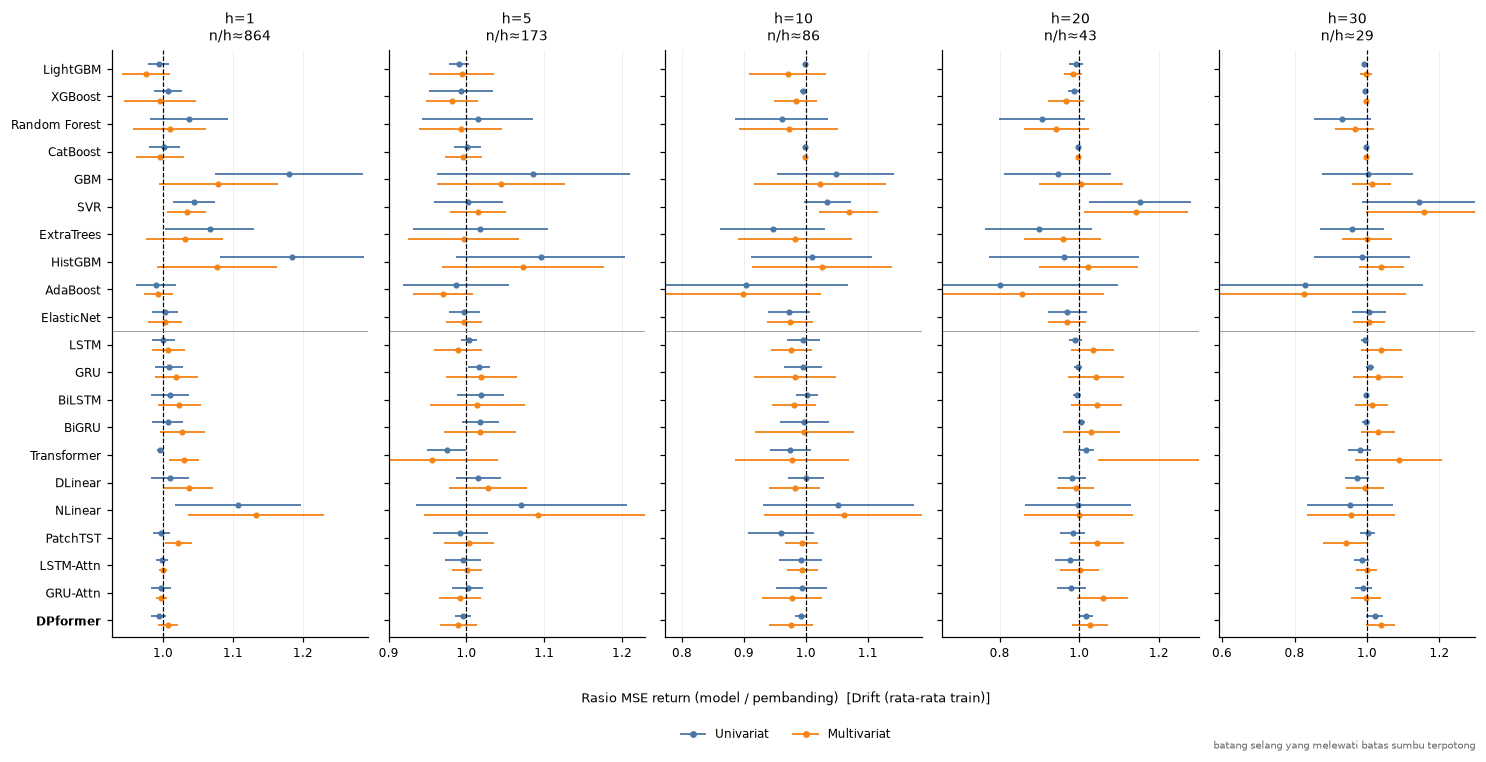

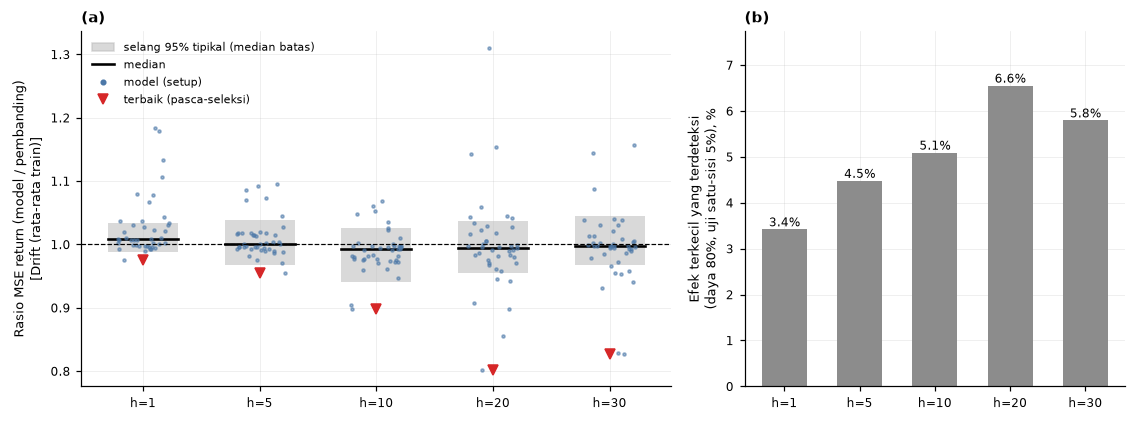

In [3]:
fig = X.fig_forest(T, ORDER, HORIZONS, 'drift')
simpan(fig, 'fig_ci_forest_drift')
fig = X.fig_ci_summary(T, HORIZONS, 'drift')
simpan(fig, 'fig_ci_ringkasan')

In [4]:
d0 = SUM[SUM.bench == 'drift'].set_index('horizon')
print('Terhadap Drift resmi (median antar kombinasi model x setup):')
for h, r in d0.iterrows():
    print(f"h={h:>2}  n/h~{r.n_eff_median:>5.0f}  selang 95% tipikal [{r.ci_lo_median:.3f}, {r.ci_hi_median:.3f}]  MDE~{r.mde_median_pct:.1f}%  "
          f"| rasio<1: {int(r['n_rel<1'])}/{int(r.n_komb)}  p<0,05: {int(r['n_p<0.05'])}  lolos BH: {int(r['n_q<0.05'])}  "
          f"| perbaikan >=5% tersingkir: {int(r.n_tersingkir_5pct)}/{int(r.n_komb)}  >=10%: {int(r.n_tersingkir_10pct)}/{int(r.n_komb)}")
display(d0[['n_komb', 'n_eff_median', 'rel_median', 'ci_lo_median', 'ci_hi_median', 'mde_median_pct',
            'n_tersingkir_5pct', 'n_tersingkir_10pct', 'n_rel<1', 'n_p<0.05', 'n_q<0.05']].round(3))

print('\nModel terbaik per horizon (rasio MSE terkecil) - PASCA-SELEKSI, hanya ilustrasi; jangan dikutip sebagai keunggulan:')
best = (T[T.bench == 'drift'].sort_values('rel_mse').groupby('horizon').head(1)
        [['horizon', 'setup', 'model', 'rel_mse', 'ci_lo', 'ci_hi', 'p_one_hln', 'q_bh']].sort_values('horizon'))
display(best.round(3).set_index('horizon'))

Terhadap Drift resmi (median antar kombinasi model x setup):
h= 1  n/h~  864  selang 95% tipikal [0.988, 1.034]  MDE~3.4%  | rasio<1: 13/42  p<0,05: 1  lolos BH: 0  | perbaikan >=5% tersingkir: 40/42  >=10%: 42/42
h= 5  n/h~  173  selang 95% tipikal [0.967, 1.038]  MDE~4.5%  | rasio<1: 19/42  p<0,05: 1  lolos BH: 0  | perbaikan >=5% tersingkir: 31/42  >=10%: 41/42
h=10  n/h~   86  selang 95% tipikal [0.941, 1.027]  MDE~5.1%  | rasio<1: 32/42  p<0,05: 4  lolos BH: 0  | perbaikan >=5% tersingkir: 17/42  >=10%: 35/42
h=20  n/h~   43  selang 95% tipikal [0.956, 1.037]  MDE~6.6%  | rasio<1: 26/42  p<0,05: 3  lolos BH: 0  | perbaikan >=5% tersingkir: 23/42  >=10%: 31/42
h=30  n/h~   29  selang 95% tipikal [0.967, 1.045]  MDE~5.8%  | rasio<1: 25/42  p<0,05: 7  lolos BH: 0  | perbaikan >=5% tersingkir: 28/42  >=10%: 33/42


,n_komb,n_eff_median,rel_median,ci_lo_median,ci_hi_median,mde_median_pct,n_tersingkir_5pct,n_tersingkir_10pct,n_rel<1,n_p<0.05,n_q<0.05
horizon,,,,,,,,,,,
1,42,864.000,1.008,0.988,1.034,3.422,40,42,13,1,0
5,42,172.800,1.001,0.967,1.038,4.478,31,41,19,1,0
10,42,86.300,0.992,0.941,1.027,5.092,17,35,32,4,0
20,42,43.050,0.995,0.956,1.037,6.553,23,31,26,3,0
30,42,28.633,0.997,0.967,1.045,5.795,28,33,25,7,0



Model terbaik per horizon (rasio MSE terkecil) - PASCA-SELEKSI, hanya ilustrasi; jangan dikutip sebagai keunggulan:


,setup,model,rel_mse,ci_lo,ci_hi,p_one_hln,q_bh
horizon,,,,,,,
1,multivariat,lightgbm,0.976,0.942,1.010,0.083,0.638
5,multivariat,transformer,0.955,0.870,1.041,0.154,0.768
10,multivariat,adaboost,0.899,0.773,1.024,0.057,0.638
20,univariat,adaboost,0.801,0.506,1.097,0.094,0.427
30,multivariat,adaboost,0.827,0.546,1.107,0.113,0.659


## 3. Uji stres: seberapa kuat Drift resmi sebagai pembanding?

Drift resmi memakai rata-rata train yang **tetap**, sedangkan periode uji adalah reli panjang: rata-rata return h-hari pada uji jauh di atas rata-rata train (tabel pergeseran level di bawah). Karena itu Drift resmi *tertinggal secara sistematis* pada h panjang, dan model yang sekadar menaikkan prediksi rata-ratanya akan tampak "mengalahkan Drift". Dua pembanding adaptif kausal (nol parameter terlatih) menguji ini:

- bila model **tidak** mengalahkan Drift ekspansif/bergulir sementara mengalahkan Drift resmi, keunggulan itu berasal dari *penyesuaian level*, bukan dari kemampuan meramal pergerakan;
- `rel_oracle_konstan` (rata-rata return **uji**; tidak layak dipakai) adalah *batas atas* penghematan MSE yang bisa dicapai oleh konstanta mana pun, jadi menunjukkan seberapa besar bagian MSE Drift yang murni berasal dari pergeseran level.

Model-model vs tiga pembanding (jumlah dari 42 kombinasi model x setup per horizon):


rasio_median  n_rasio<1  n_p<0.05  \
pembanding                       horizon                                      
Drift (rata-rata train)          1               1.008         13         1   
                                 5               1.001         19         1   
                                 10              0.992         32         4   
                                 20              0.995         26         3   
                                 30              0.997         25         7   
Drift ekspansif (kausal)         1               1.009         12         1   
                                 5               1.007         13         1   
                                 10              1.003         19         0   
                                 20              1.014         13         0   
                                 30              1.021          9         0   
Drift bergulir 250 hari (kausal) 1               1.012          8         0   
                                 5               1.026          3         0   
                                 10              1.037          3         0   
                                 20              1.085          4         0   
                                 30              1.113          2         0   

                                          n_lolos_BH  n_komb  
pembanding                       horizon                      
Drift (rata-rata train)          1                 0      42  
                                 5                 0      42  
                                 10                0      42  
                                 20                0      42  
                                 30                0      42  
Drift ekspansif (kausal)         1                 0      42  
                                 5                 0      42  
                                 10                0      42  
                                 20                0      42  
                                 30                0      42  
Drift bergulir 250 hari (kausal) 1                 0      42  
                                 5                 0      42  
                                 10                0      42  
                                 20                0      42  
                                 30                0      42

Pergeseran level: rata-rata return h-hari train vs uji, dan MSE pembanding relatif terhadap Drift resmi:


,n,mu_train_pct,mean_uji_pct,rel_drift_exp,rel_drift_roll,rel_oracle_konstan,maks_hemat_konstan_pct
horizon,,,,,,,
1,864,0.0295,0.1081,0.9989,0.9964,0.9935,0.6534
5,864,0.1446,0.5374,0.9941,0.9762,0.9668,3.3166
10,863,0.2919,1.0847,0.9893,0.9569,0.9375,6.2486
20,861,0.5959,2.1798,0.9815,0.9165,0.8844,11.5650
30,859,0.9078,3.3477,0.9772,0.8958,0.8407,15.9259


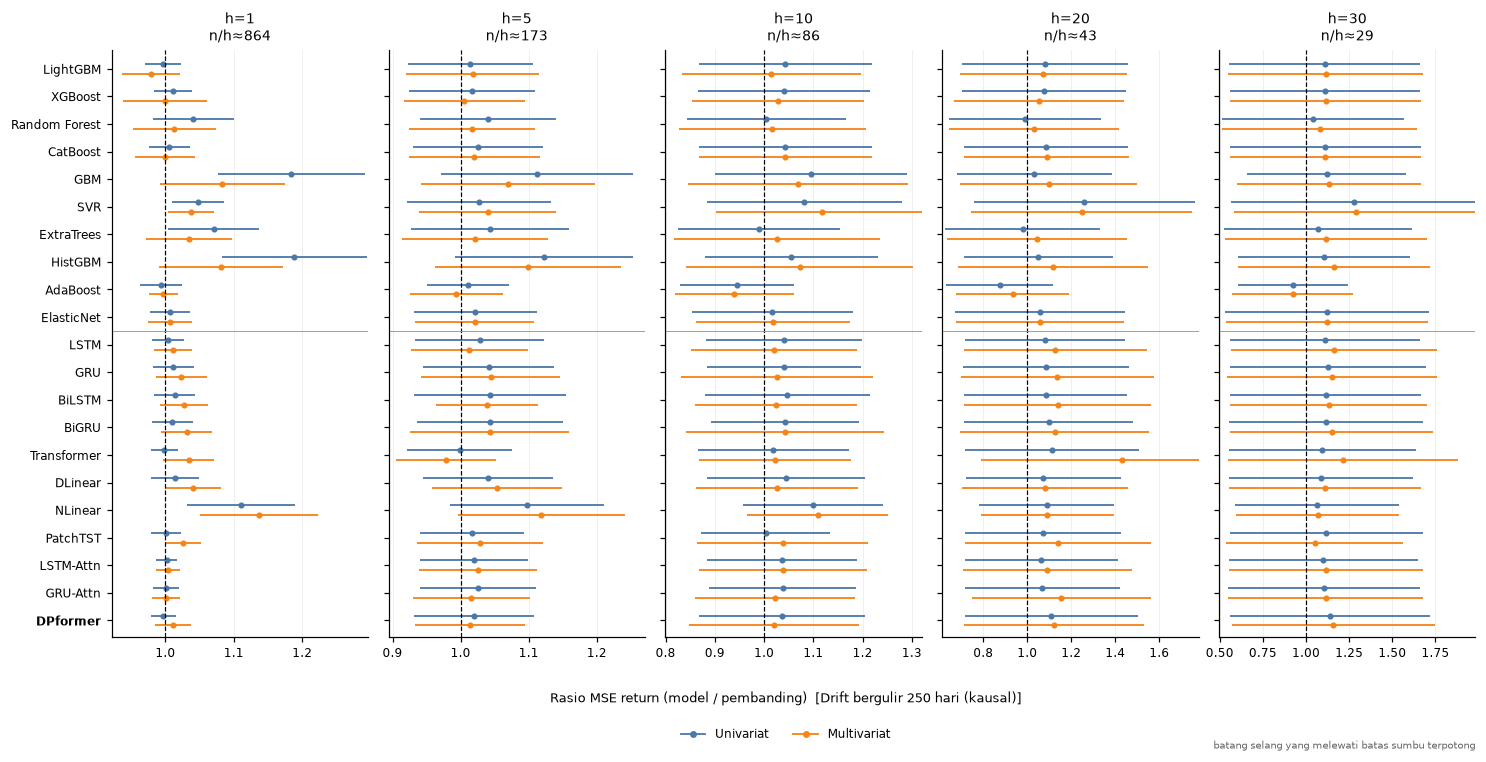

In [5]:
rows = []
for b in X.BENCH:
    s = SUM[SUM.bench == b].set_index('horizon')
    rows.append(pd.DataFrame({'pembanding': X.bench_label(b), 'rasio_median': s.rel_median, 'n_rasio<1': s['n_rel<1'],
                              'n_p<0.05': s['n_p<0.05'], 'n_lolos_BH': s['n_q<0.05'], 'n_komb': s.n_komb}))
stres = pd.concat(rows).reset_index().set_index(['pembanding', 'horizon'])
print('Model-model vs tiga pembanding (jumlah dari 42 kombinasi model x setup per horizon):')
display(stres.round(3))
print('Pergeseran level: rata-rata return h-hari train vs uji, dan MSE pembanding relatif terhadap Drift resmi:')
LS = X.level_shift_table(p, HORIZONS)
display(LS.round(4).set_index('horizon'))
fig = X.fig_forest(T, ORDER, HORIZONS, 'drift_roll')
simpan(fig, 'fig_ci_forest_drift_bergulir')

**Cara membaca.**

- **Selang.** Di antara 42 kombinasi per horizon, hitung berapa yang batas bawahnya > 0,95: untuk kombinasi itu, perbaikan MSE ≥ 5% **sudah tersingkir** pada tingkat 95%. Selang yang lebar (mis. h = 20/30 pada AdaBoost) berarti hasilnya *tidak informatif*, bukan "tidak ada efek".
- **MDE.** Pada h panjang jumlah jendela independen kecil (n/h), sehingga hanya perbaikan yang cukup besar yang bisa terlihat. Kalimat yang aman untuk naskah: *"dengan sekitar n/h jendela independen, uji kami berdaya 80% hanya untuk perbaikan MSE ≥ MDE%; hasil nol karenanya tidak menyingkirkan perbaikan yang lebih kecil."* (ambil n/h dan MDE dari tabel di atas).
- **Model terbaik per horizon** hanyalah yang kebetulan terbaik dari 42; selangnya tetap memuat 1. Jangan dikutip sebagai bukti keunggulan.
- **Uji stres.** Bila jumlah model yang mengalahkan Drift bergulir pada h ≥ 5 jauh lebih sedikit daripada yang mengalahkan Drift resmi, tulis di naskah bahwa Drift resmi adalah pembanding yang lemah pada rezim reli dan keunggulan atasnya tidak boleh ditafsirkan sebagai kemampuan meramal. Protokol utama tetap memakai Drift resmi; ini analisis sensitivitas.
- **Yang tidak boleh ditulis:** "tidak ada hubungan", "model tidak berguna", atau mengutip p < 0,05 tanpa koreksi BH. Tulis: "tidak ada bukti bahwa model mengalahkan Drift pada return, dan uji ini hanya mampu mendeteksi perbaikan ≥ MDE%".